# CS 3110/5110: Data Privacy

## In-Class Exercise, week of 10/19/2026


In [ ]:
# Load the data and libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt


def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)


def laplace_mech_vec(vec, sensitivity, epsilon):
    return [
        v + np.random.laplace(loc=0, scale=sensitivity / epsilon) for v in vec
    ]


def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(
        loc=0, scale=sensitivity * np.sqrt(2 * np.log(1.25 / delta)) / epsilon
    )


def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [
        v
        + np.random.normal(
            loc=0,
            scale=sensitivity * np.sqrt(2 * np.log(1.25 / delta)) / epsilon,
        )
        for v in vec
    ]


def pct_error(orig, priv):
    return np.abs(orig - priv) / orig * 100.0


adult = pd.read_csv(
    "https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv"
)
retail = pd.read_csv(
    "https://github.com/jnear/cs3110-data-privacy/raw/main/homework/retail.csv"
)

In [2]:
def gaussian_mech_RDP(val, sensitivity, alpha, epsilon):
    sigma = np.sqrt((sensitivity**2 * alpha) / (2 * epsilon))
    return val + np.random.normal(loc=0, scale=sigma)

## Question -1

Use the _regular_ (not vector-valued) Laplace mechanism, **with advanced composition**, to construct a noisy CDF of ages.


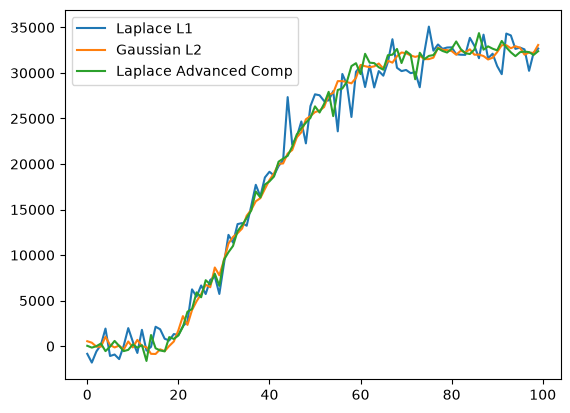

In [ ]:
def age_cdf():
    a = adult["Age"]
    return [len(a[a < i]) for i in range(100)]


# L1 Sensitivity; no composition
def laplace_cdf(epsilon):
    return laplace_mech_vec(age_cdf(), 100, epsilon)


# L2 Sensitivity; no composition
def gaussian_cdf(epsilon, delta):
    return gaussian_mech_vec(age_cdf(), np.sqrt(100), epsilon, delta)


# L1 Sensitivity; advanced composition
def laplace_cdf_advanced_composition(epsilon, delta):
    # OPTION A:
    # cdf_output = []
    # for v in age_cdf():
    #     cdf_output.append(laplace_mech(v, sensitivity=1, epsilon=epsilon))

    # return cdf_output

    # Total Privacy cost is (100*epsilon, 0 [delta here is zero])-DP by sequential composition
    # OR
    # Total Privacy cost is epsilon' = (sqrt(2k * log(1/delta)) * epsilon +
    # k*epsilon * (e^epsilon - 1), delta)-DP by advanced composition.
    # This gives us an epsilon value that is larger than 1.
    # (This^ is Option A in my notes: calculate total epsilon afterwards)
    # (Option B: use algebra to set epsilon_i in such a way that we achieve the
    # total epsilon that we have targetted)
    # So using epsilon and
    # delta as modifiable parameters, we need to pick appropriate values to
    # ensure the total privacy cost (epsilon') equals the value we are
    # targetting.
    # OPTION B:
    cdf_output = []
    k = len(age_cdf())  # number of loop iterations
    epsilon_i = epsilon / np.sqrt(2 * k * np.log(1 / delta))
    for v in age_cdf():
        cdf_output.append(laplace_mech(v, sensitivity=1, epsilon=epsilon_i))

    return cdf_output


plt.plot(laplace_cdf(0.1), label="Laplace L1")
plt.plot(gaussian_cdf(0.1, 1e-5), label="Gaussian L2")
plt.plot(
    laplace_cdf_advanced_composition(0.1, 1e-5), label="Laplace Advanced Comp"
)
plt.legend()

## Question 1

Consider the retail dataset and the following counting query on it. What is the query's sensitivity?


In [8]:
def retail_query():
    return len(retail[retail["CustomerID"] == 12748])


retail_query()

81

The sensitivity is technically unbounded, because it is equal to the maximum
number of orders a person could make, and there is no upper bound on that.


## Question 2

What are we actually protecting in the retail dataset, when the unit of privacy is set to:

1. Event-level / row-level
2. Person-level / user-level


YOUR ANSWER HERE


## Question 3

What is the _effective_ person-level $\epsilon$ value for the following query, which assumes a row-level unit of privacy?


In [ ]:
def dp_retail_query():
    result = retail_query()
    return laplace_mech(result, sensitivity=1, epsilon=1)


dp_retail_query()

YOUR ANSWER HERE


## Question 4

Use _contribution bounding_ to adjust the unit of privacy to be person-level privacy, and implement a differentially private function to return the orders originating from the United Kingdom.


In [ ]:
def bound_contributions(bound):
    # YOUR CODE HERE
    raise NotImplementedError()


def dp_retail_query(bound, epsilon):
    # YOUR CODE HERE
    raise NotImplementedError()


dp_retail_query(100, 1.0)

In [ ]:
# TEST CASE

results = [dp_retail_query(100, 1.0) for _ in range(100)]
errors = [
    pct_error(len(retail[retail["Country"] == "United Kingdom"]), r)
    for r in results
]
print("mean error:", np.mean(errors))

assert np.mean(errors) > 20
assert np.mean(errors) < 50

## Question 5

Write a function to calculate the L1 **local sensitivity** of the following mean query.


In [ ]:
def mean_query():
    b = 125
    return (
        adult["Age"][adult["Education"] == "Bachelors"]
        .clip(lower=0, upper=b)
        .mean()
    )


mean_query()

In [ ]:
def mean_query_local_sensitivity():
    # YOUR CODE HERE
    raise NotImplementedError()


mean_query_local_sensitivity()

In [ ]:
# TEST CASE
assert (mean_query_local_sensitivity() - 0.02333831217326363) < 0.0001

## Question 6

Why can't we use the local sensitivity from question 1 directly to achieve differential privacy for `mean_query`?


YOUR ANSWER HERE


## Question 7

Calculate the empirical _cumulative distribution function_ of ages in the adult dataset. Use the RDP Gaussian mechanism.


In [ ]:
def calculate_cdf():
    alpha = 5
    epsilon = 0.0001

    # YOUR CODE HERE
    raise NotImplementedError()


cdf_vals = calculate_cdf()
plt.plot(range(20, 80), cdf_vals)

## Question 8

What is the _total privacy cost_ in RDP of your solution above?


YOUR ANSWER HERE


## Question 9

What is the _total privacy cost_ in $(\epsilon, \delta)$-differential privacy of your solution above, for $\delta = 10^{-5}$?


YOUR ANSWER HERE


## Question 10

Repeat the earlier question, but for zero-concentrated differential privacy.


In [ ]:
def gaussian_mech_zCDP(val, sensitivity, rho):
    # YOUR CODE HERE
    raise NotImplementedError()


def calculate_cdf_zcdp():
    rho = 0.00001

    # YOUR CODE HERE
    raise NotImplementedError()


cdf_vals = calculate_cdf_zcdp()
plt.plot(range(20, 80), cdf_vals)